# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student 

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.

### How to use this notebook
- Run cells top to bottom. Cells starting with `!` run shell commands.
- Change `MODEL` / `MODEL2` below if the model names differ on your installation.
- Fill in the **✍️ Your answer** cells — they feed your final report.

## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [ ]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

In [ ]:
!pip --version

### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [1]:
!ollama --version

]11;?\ollama version is 0.40.7


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [2]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
If the exact name differs on your installation, pick a small instruct/chat model suited to your hardware.

In [7]:
# Models used throughout the lab — edit if needed
MODEL  = "qwen3.5:4b"   # Model 1
MODEL2 = "gemma3:4b"    # Model 2 (used in the comparison parts)

In [8]:
!ollama pull {MODEL}

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest 
pulling e56a899b1540: 100% ▕██████████████████▏ 675 MB                         
pulling a9d0a3e1d8c9: 100% ▕██████████████████▏ 2.6 GB                         
pulling b507b9c2f6ca: 100% ▕██████████████████▏   13 B                         
pulling 50cbab8a892c: 100% ▕██████████████████▏  11 KB                         
pulling 9371364b27a5: 100% ▕██████████████████▏   65 B                         
pulling 788a4d94bc3f: 100% ▕██████████████████▏  177 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 


In [9]:
!ollama list

]11;?\NAME                ID              SIZE      MODIFIED       
qwen3.5:4b          d8b0f5e9760c    3.3 GB    14 seconds ago    
gemma3:4b           68ceab7e468a    3.4 GB    7 minutes ago     
qwen2.5-coder:7b    dae161e27b0e    4.7 GB    5 months ago      


### Exercise 4 — Run the model
In the terminal you would use `ollama run qwen3.5`. Here we do the same thing through the API with a helper function.

In [10]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [11]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[31.9s]
Artificial intelligence is a branch of computer science focused on creating systems capable of performing tasks that usually require human intelligence. These systems can learn, reason, perceive their environment, and adapt to new information without being explicitly programmed for every possible situation. By processing massive datasets and identifying complex patterns, AI enhances decision-making efficiency across industries like healthcare, finance, and transportation. Practical applications range from personal assistants providing recommendations to advanced self-driving cars navigating roads autonomously. Ultimately, the goal of artificial intelligence is to augment human capabilities while continuously advancing through algorithms driven by data analysis.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[28.1s]
Imagine you are trying to teach your younger brother how to pick up a dog’s n

### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

**✍️ Your answer:**

1. Yes, the model produced different answers because each prompt specified a different audience or format. It gave a five-sentence overview, a simpler explanation with examples for a child, and a more detailed technical explanation for a professor. Some statements were inaccurate, so the answers still need verification.

2. No. Python sends requests to Ollama's local API at `localhost:11434`, not to a cloud API.

3. Inference is performed locally on the computer running Ollama, using its CPU and/or GPU.

4. The model should continue working without Internet because it is already downloaded and inference runs locally..

## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [12]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[63.9s]
Good morning, everyone. Please settle down and take your seats. Today, we are going to dive into a fundamental concept that underpins much of computer science, logic design, and data flow. We will be discussing the **Directed Acyclic Graph**, or **DAG** for short.

To understand it properly, let's break it down into its constituent parts.

### 1. Definition

A Directed Acyclic Graph (DAG) is a mathematical structure used to represent relationships between objects. To define it formally:

1.  **Directed**: The edges (links between nodes) have direction. If there is an edge from $A$ to $B$, you can move from $A$ to $B$, but not necessarily the other way around (unlike an undirected graph).
2.  **Acyclic**: This is the crucial distinguishing factor. There must be no cycles. You cannot trace a path that starts at a node and eventually returns to that same node. If you start at Node X, you will never arrive back at Node X again by following directed edges.

This structure guarantees

In [13]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[41.5s]
Hello there! Welcome to the department of Computer Science logic. I am glad you're here. We are going to talk about something fundamental that appears in software projects, databases, and data science every single day. We call them **DAGs**.

That stands for **Directed Acyclic Graph**. It sounds complicated on first hearing, but let’s break it down into plain English.

### 1. What do these words actually mean?

Imagine you are walking through a maze. A DAG is just a way of describing how your path works using three simple rules:

*   **Graph:** This is simply a diagram where things are connected to each other with lines. Think of it like a web or a map.
*   **Directed:** This means the arrows (lines) have a specific direction. It's like a one-way street. If there is an arrow from Point A to Point B, you can only go from A to B. You cannot turn around and drive back to A immediately.
*   **Acyclic:** This is the most important part. "Cyclic" means looping in a circle (like a cir

### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**✍️ Your answer:**

Both answers explain DAGs, but the first is more formal, with mathematical notation and topological ordering. The second is more conversational and uses a sandwich-making analogy.

- **Role:** Tells the model which perspective or tone to adopt, such as a computer science professor.
- **Context:** Identifies the audience and situation, helping the model choose suitable vocabulary and examples.
- **Constraints:** Set limits, such as length or required content. Without strict limits, answers can become lengthy.
- **Output format:** Defines how to organize the response, such as a definition, example, and Python code.
- **Specificity:** Clear, detailed instructions give more control over the answer. Broad instructions allow more variation in style and content.

## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [14]:
!ollama list

]11;?\NAME                ID              SIZE      MODIFIED       
qwen3.5:4b          d8b0f5e9760c    3.3 GB    10 minutes ago    
gemma3:4b           68ceab7e468a    3.4 GB    17 minutes ago    
qwen2.5-coder:7b    dae161e27b0e    4.7 GB    5 months ago      


In [19]:
!ollama show {MODEL}

]11;?\  Model
    architecture        qwen35             
    parameters          4.2B               
    context length      262144             
    embedding length    2560               
    quantization        Q4_K_M             
    requires            0.30.0             
    renderer            qwen3.5            
    parser              qwen3.5            
    template source     renderer_parser    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          333.51M    
    embedding length    1024       
    dimensions          2560       

  Parameters
    presence_penalty    1.5     
    temperature         1       
    top_k               20      
    top_p               0.95    

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [18]:
!ollama ps

]11;?\NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen3.5:4b    d8b0f5e9760c    3.1 GB    100% GPU     4096       llamacpp    4 minutes from now    


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [20]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:4b,3.32,qwen35,4.2B,Q4_K_M
1,gemma3:4b,3.35,gemma3,3.9B,Q4_K_M
2,qwen2.5-coder:7b,4.68,qwen2,7.6B,Q4_K_M


Currently loaded in memory:


,name,size_GB,in_VRAM_GB,expires_at
0,qwen3.5:4b,3.14,3.14,2026-10-21T14:28:53.49077485+01:00


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**✍️ Your answer:**

- `ollama list` shows models downloaded on disk, including their names, IDs, sizes, and modification dates. My computer has three downloaded models: `qwen3.5:4b`, `gemma3:4b`, and `qwen2.5-coder:7b`.

- `ollama ps` shows models currently loaded in memory, including their memory usage, CPU/GPU allocation, and remaining keep-alive time. Currently, only `qwen3.5:4b` is loaded; the API output reports approximately 3.14 GB in GPU memory.

- A **downloaded** model is stored on disk and remains available after restarting. A **loaded** model has been placed in RAM and/or VRAM for inference. It can be unloaded after inactivity while its downloaded files remain on disk.

## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [21]:
!ollama pull {MODEL2}
!ollama list

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest 
pulling f06e91e18fc7: 100% ▕██████████████████▏ 2.5 GB                         
pulling 7a50f9607a47: 100% ▕██████████████████▏ 851 MB                         
pulling e0a42594d802: 100% ▕██████████████████▏  358 B                         
pulling dd084c7d92a3: 100% ▕██████████████████▏ 8.4 KB                         
pulling 3116c5225075: 100% ▕██████████████████▏   77 B                         
pulling 4bf7b0a45f1a: 100% ▕██████████████████▏  144 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 
]11;?\NAME                ID              SIZE      MODIFIED       
gemma3:4b           68ceab7e468a    3.4 GB    5 seconds ago     
qwen3.5:4b          d8b0f5e9760c    3.3 GB    16 minutes ago    
qwen2.5-coder:7b    dae161e2

### Exercise 7 — Same prompt, different models

In [23]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3.5:4b

Here's a Python function that determines whether a number is prime, fully documented with type hints and detailed explanations:

```python
import math

def is_prime(n: int) -> bool:
    """
    Determine whether a given integer is prime.

    This function uses trial division to check for divisors from 2 up to the 
    square root of n. It includes optimizations such as eliminating even numbers 
    except 2 itself.

    Args:
        n (int): The number to test for primality. Must be a non-negative integer.

    Returns:
        bool: True if n is prime, False otherwise.
    
    Raises:
        TypeError: If input is not an integer.
    
    Examples:
        >>> is_prime(2)
        True
        >>> is_prime(17)
        True
        >>> is_prime(18)
        False
    """
    if not isinstance(n, int):
        raise TypeError("Input must be an integer.")

    # Negative numbers and zero are not prime
    if n < 2:
        return False
    
    # 2 and 3 are both pri

Now fill in your evaluation (scores out of 5) and see the table:

In [26]:
scores = {
    MODEL:  {"Response quality /5": 4, "Code correctness /5": 5},
    MODEL2: {"Response quality /5": 4, "Code correctness /5": 4},
}

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5:4b,16.6,4,5
1,gemma3:4b,12.8,4,4


**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [28]:
# Qwen's function
def is_prime_qwen(n: int) -> bool:
    if not isinstance(n, int):
        raise TypeError("Input must be an integer.")

    if n < 2:
        return False
    if n <= 3:
        return True
    if n % 2 == 0 or n % 3 == 0:
        return False

    i = 5
    while i * i <= n:
        if n % i == 0 or n % (i + 2) == 0:
            return False
        i += 6

    return True


# Gemma's function
def is_prime_gemma(n: int) -> bool:
    if n <= 1:
        return False

    for i in range(2, int(n**0.5) + 1):
        if n % i == 0:
            return False

    return True


# Compare both against the reference
for name, candidate in [
    ("qwen3.5:4b", is_prime_qwen),
    ("gemma3:4b", is_prime_gemma),
]:
    mismatches = [
        n for n in range(-5, 2000)
        if candidate(n) != is_prime_reference(n)
    ]
    assert not mismatches, f"{name}: incorrect results for {mismatches}"
    print(f"{name} matches the reference from -5 to 1999")

qwen3.5:4b matches the reference from -5 to 1999
gemma3:4b matches the reference from -5 to 1999


### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**✍️ Your answer:**

- **Speed:** Qwen took 16.6 seconds. Gemma's response time was not included in the supplied output, so I cannot determine which was faster yet.
- **Code quality:** I prefer Qwen's implementation because it skips multiples of 2 and 3 and uses integer arithmetic. Both algorithms have O(√n) time complexity and O(1) auxiliary space. However, Qwen's mathematical explanation contains an error.
- **Memory:** Gemma's downloaded file is slightly larger (3.35 GB versus 3.32 GB). Actual inference memory usage must be measured with each model loaded; disk size alone is insufficient.
- **Programming assistance:** I would choose Qwen for this task because its implementation is more efficient, while still checking its explanations and testing the generated code.
- **Model size:** The largest model is not necessarily the best. Task suitability, correctness, speed, and memory requirements also matter.

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [29]:
!pip install -q requests

In [30]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [ ]:
%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

In [31]:
%%writefile local_ai_lab/requirements.txt
requests

Overwriting local_ai_lab/requirements.txt


In [32]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Overwriting local_ai_lab/README.md


In [33]:
!python local_ai_lab/app.py

Recursion is one of the most fundamental concepts in computer science. In Python, it allows a function to call itself to solve a problem that can be broken down into smaller, identical sub-problems.

Here is a complete guide to understanding and using recursion in Python.

---

### 1. The Core Concept
Think of recursion like **Russian Nesting Dolls**. To open the outer box, you have to open the inner doll. If you open that, you find a smaller doll inside it. You keep opening them until you reach a "base" doll where there is nothing inside (the **Base Case**).

In code terms:
1.  **The Function calls itself.**
2.  There must be a stopping point; otherwise, the function will run forever.

### 2. The Two Essential Parts of Recursion
Every recursive function needs two things to work correctly:

1.  **Base Case (Stop Condition):** A condition that stops the recursion. Without this, you enter an infinite loop and crash your program.
2.  **Recursive Step:** The part where the function calls i

**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [34]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

# What is Recursion in Python?

**Recursion** is a powerful programming technique where a function calls itself to solve a problem. Instead of performing all the work in one go, the function breaks the task down into smaller sub-problems that are similar to the original problem.

Think of it like opening a set of Russian nesting dolls or taking an elevator: you keep moving from one floor to another until you reach the ground floor (the base case), and then you start your way back up, closing each doll/floor as you go.

---

## The Anatomy of Recursion
To write a correct recursive function in P ...

{'model': 'qwen3.5:4b', 'created_at': '2026-10-21T13:44:05.228507178Z', 'done': True, 'done_reason': 'stop', 'total_duration': 44854026184, 'load_duration': 1078155, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 12, 'prompt_eval_duration': 380712000, 'eval_count': 2632, 'eval_duration': 44236916000, 'wall_s': 44.913844564999636}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [37]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

chat_loop_stateless()

Local AI Assistant
Type 'exit' to stop.

AI: 

AI: Hey there! How can I help you today? 😊

AI: The terms **Data Science (DS)** and **Data Engineering (DE)** are often used interchangeably, but they represent two distinct specializations within the technology and analytics sector. While they work closely together, their goals, skill sets, and daily tasks differ significantly.

Here is a comprehensive breakdown of the differences between them.

---

### 1. The Core Philosophy
*   **Data Engineering (DE): "Building the Pipes"**
    Data Engineers focus on the infrastructure required to make data accessible. They build systems that collect, store, clean, and move data reliably so others can use it. Without them, there is no structured data for analysts or scientists to look at.
*   **Data Science (DS): "Extracting Meaning from the Pipes"**
    Data Scientists focus on analyzing, interpreting, and predicting trends within the data. They turn raw information into insights, visualizations, an

In [36]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: At its simplest, **Machine Learning (ML)** is a subset of Artificial Intelligence (AI) that gives computers the ability to learn from data without being explicitly programmed with specific rules for every scenario.

Instead of telling a computer exactly how to perform a task step-by-step (like traditional programming), machine learning algorithms provide data and let the system figure out the patterns on its own.

Here is a breakdown of how it works, the main types, and why it matters.

### 1. H ...

You: Explain reinforcement learning.
AI: Reinforcement Learning (RL) is a branch of Machine Learning where an intelligent agent learns to make decisions by interacting with its environment. Instead of being given a dataset of labeled answers (like supervised learning), the agent must figure out what to do through **trial and error**.

Here is a detailed breakdown of how it works, its components, and its role in modern AI.

---

### 1. The Core Concept: Tr

## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [39]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

chat_loop_memory()


AI: Hello Loubna! It is great to meet you. 

Being a PhD researcher at the intersection of AI and cybersecurity is an exciting and impactful field. There are so many dynamic topics emerging, especially regarding adversarial machine learning, secure deep learning architectures, privacy-preserving techniques, and explainable AI in security contexts.

Is there something specific you'd like help with today? I can assist with things like:
*   Literature reviews or finding relevant papers
*   Debugging or explaining code snippets (Python, TensorFlow, PyTorch, etc.)
*   Structuring research ideas or drafts
*   Discussing technical challenges you are facing

Just let me know where your focus is right now!

AI: Your name is **Loubna**, and you are a **PhD researcher in AI and cybersecurity**.

I remember you mentioned the field well! What would you like to tackle next today? Perhaps we can dive into some specific research papers or work on a code project related to your field.


In [40]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Nice to meet you, Ahmed! How can I assist you today? 

You: What is my name?
AI : Your name is Ahmed! 



In [42]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Nice to meet you, Ahmed! How can I assist you today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**✍️ Your answer:**

The model recalls the name because the application includes previous messages in each new request. The printed prompt contains “My name is Ahmed,” so the model can use that information to answer.

The LLM is not storing personal memories or updating its weights between calls. The application maintains the conversation history and sends it again, either as text in the prompt or as structured messages through `/api/chat`.

Without that history, the model would not know the name from the previous request.

---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [43]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Your name is Ahmed.


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [44]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[50.5s]
Here is a comprehensive review of the provided Java code from the perspective of a Senior Developer.

### 1. Potential Problems

*   **Division by Zero:** This is the most critical design flaw. If `b` is zero, attempting the division will cause an immediate termination of the JVM unless handled explicitly in the calling thread.
*   **Lack of Input Validation:** There is no contract or documentation specifying what inputs are acceptable (e.g., must not be negative? must fit within integer range?). This makes it difficult to ensure correctness for downstream consumers.
*   **Data Loss/Truncation:** Using `int` implies truncating decimal results. If the caller expects precise calculations, they will get incorrect results without any indication of precision loss.
*   **Lack of Documentation (Javadoc):** There are no comments describing what the method does, the expected inputs, or potential exceptions.
*   **Type Rigidity:** The signature is rigid (`int` only). This makes extending

In [45]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[27.5s]
### The Bug

There is a **logical error in the `setAge` method**.

**Location:** Inside `public void setAge(int age) { age = age; }`

**The Problem:**
In Java, primitive types (like `int`) are passed by **value**, not reference. Furthermore, assigning the parameter variable to itself (`age = age`) has no effect. You cannot modify a local parameter variable and affect the object's internal state (`this.age`). This method is effectively a "No-Op" (Null Operation).

**The Consequence:**
Whenever you call `student.setAge(20)`, the instance variable `age` remains whatever it was initialized to (or its default value, which is `0` for integers). You can never change the student's age using this class.

---

### How to Fix It

To fix the bug, you must explicitly assign the parameter value to the **instance variable** of the object. This requires using the `this.` reference to distinguish between the local parameter and the class field.

**Corrected Code:**
```java
public void setAge(in

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [46]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[1.7s]
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "Low",
  "recommendation": "Continue current support; minimal intervention required due to excellent academic performance and low absenteeism."
}


In [47]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'Low', 'recommendation': 'Continue current support; minimal intervention required due to excellent academic performance and low absenteeism.'}


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [48]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "low",
  "recommendation": "Maintain current academic performance and attendance; monitor for any future dips in engagement."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

**✍️ Your answer:**

Structured output lets an application parse, validate, and use the model’s response automatically, with predictable fields and data types.

In the first response, the JSON was valid, but `"risk": "Low"` did not match the schema’s allowed lowercase values. Using the JSON Schema produced `"risk": "low"` and preserved `grade` as a number, parsed into a Python `float`.

This makes integration more reliable. However, a correct structure does not guarantee correct content: the risk assessment still needs defined grading rules and validation.

## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [49]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [50]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [51]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[13.0s]
Reinforcement learning learns through interaction with an environment using rewards and penalties.

[0.2s]
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?**

✍️ Your observation:**

The model followed the instruction in both tests. Its reinforcement learning answer matches the supplied document. Since the document contains no information about quantum computing, it correctly replied “Information not available.”

It respected the instruction in these examples, but more tests are needed to determine how consistently it does so.

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [52]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['reinforcement_learning.txt',
 'course.txt',
 'ai.txt',
 'deep_learning.txt',
 'machine_learning.txt']

In [53]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [54]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
  (15.0s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 8.42789552798877)]
  A: GPUs.
  (0.3s)

Q: What is supervised learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Supervised learning uses labelled data.
  (0.3s)

Q: Who won the 2018 World Cup?
  retrieved: []
  A: Information not available.
  (0.3s)



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [57]:
EMBED_MODEL = "nomic-embed-text"
!ollama pull {EMBED_MODEL}      # <- uncomment once

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

]11;?\pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest 
pulling 970aa74c0a90:   0% ▕                  ▏  62 KB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   0% ▕                  ▏ 1.1 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   1% ▕                  ▏ 1.8 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   1% ▕                  ▏ 3.2 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   2% ▕                  ▏ 4.5 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   2% ▕                  ▏ 5.9 MB/274 MB                  pulling manifest 
pulling 970a

## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [58]:
VISION_MODEL = MODEL2   # change to a vision-capable model you have installed
IMAGE_PATH = "image.png"  # put an image next to the notebook

Okay, let's analyze the image:

**1. Main Objects:**

*   **Laptop:** A silver Apple MacBook Pro (likely a 15-inch model based on its size) is the primary subject.
*   **Monitor:** The laptop screen is prominently displayed.
*   **Keyboard:** The physical keyboard of the MacBook is visible.
*   **Trackpad:**  The trackpad is also visible.


**2. Environment:**

*   **Surface:** The laptop sits on a light gray or neutral-colored surface (likely a table or desk).
*   **Background:** The background is a solid, light gray, providing a clean and uncluttered backdrop.

**3. Text Visible in the Image:**

*   **Desktop Wallpaper:** The screen displays a vibrant desktop wallpaper featuring a stylized landscape of red rock formations (similar to the Grand Canyon) with a starry night sky and a large, stylized sun. The text “Redstone” is visible on the wallpaper.
*   **Icons:**  Several icons are visible in the taskbar (e.g., Mail, FaceTime, Safari, etc.).
*  **System Menu:** The Apple menu is vis

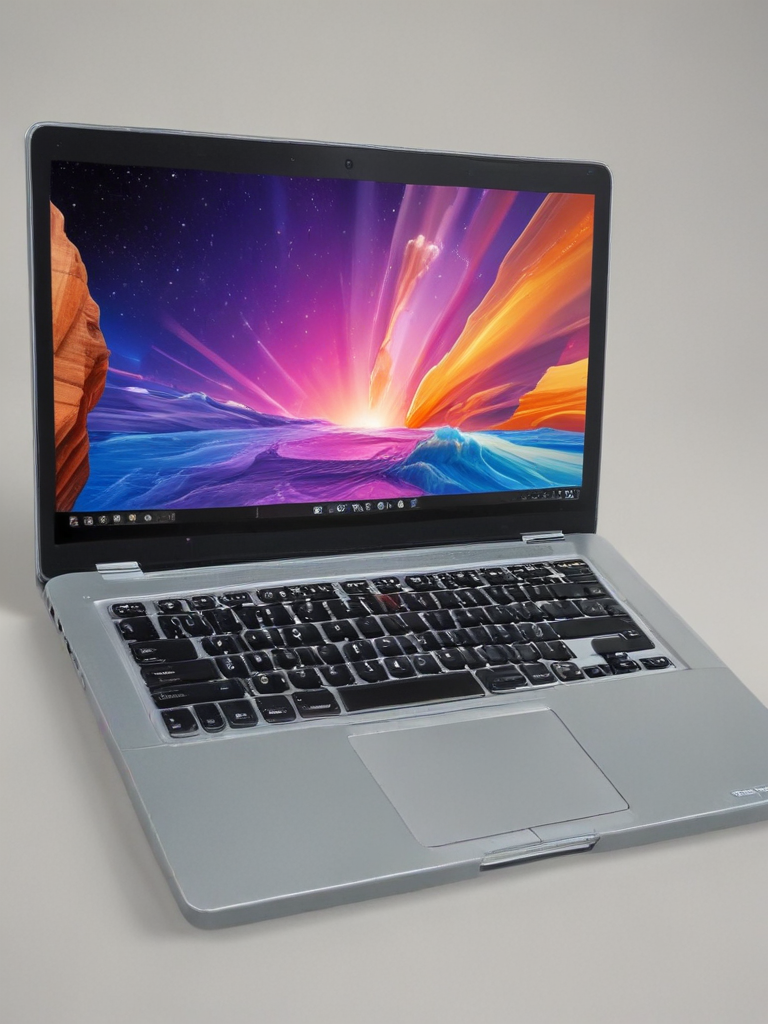

In [59]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

**✍️ Your answer:**

- **LLM vs multimodal model:** A text-only LLM processes text, while a multimodal model can also process other inputs, such as images, and answer questions about them.

- **Additional information:** The vision model receives the image alongside the text prompt. It can analyze objects, colors, layout, and visible text. However, details such as the exact laptop model or screen text may be guessed incorrectly and need verification.

- **Applications:** Local vision AI can support document analysis, OCR, industrial defect detection, educational assistance, medical-image preprocessing, and surveillance analysis. Local processing helps keep sensitive images on the computer.

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [60]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)

In [61]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Writing local-ai-web/app.py


In [62]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [63]:
!pip install -q psutil

In [64]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [67]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = 4   # <- fill in after reading both answers
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5:4b,3.32,3.14,3.14,35.11,47.25,731,61.39,48.2,4
1,gemma3:4b,3.35,2.88,2.88,7.97,20.03,800,67.56,58.8,4


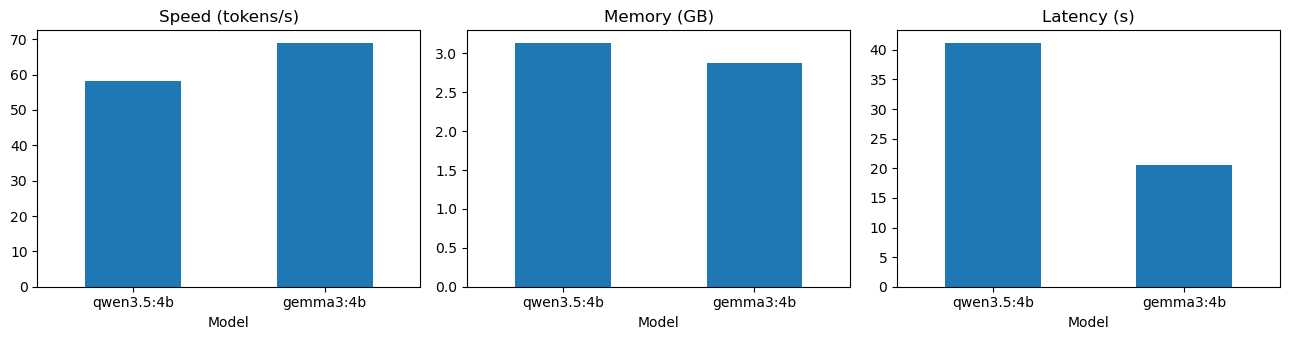

In [66]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

**✍️ Your discussion:**

Both models occupy similar disk space: 3.32 GB for Qwen and 3.35 GB for Gemma. However, Gemma used less VRAM (2.88 GB versus 3.14 GB) and completed the request faster (20.59 s versus 41.24 s). Its generation speed was also higher: 69.07 versus 58.23 tokens/s. Qwen's longer loading time (26.50 s versus 8.67 s) contributed substantially to its slower cold-start response.

For this machine, Gemma offers better measured speed and VRAM efficiency. Answer quality was not assessed in this benchmark, so these results do not establish which model gives better explanations. Model selection should balance measured performance, available hardware, and verified answer quality rather than model size alone.

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [68]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# copy shared modules and documents into the deliverable layout
shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [69]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5:4b"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [70]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import json, os, time
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # Bind to localhost ONLY (see report question Q15 on security)
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [71]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [72]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web UI → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5 gemma3
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [75]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

try:
    for q, s in [("What is reinforcement learning?", False),
                 ("And how is it different from supervised learning?", False),   # tests history
                 ("Summarize deep learning", True),                              # structured
                 ("What is quantum computing?", False)]:                         # not in the docs
        j = app_ask(q, s)
        print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
              f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")
finally:
    pass  # keep running so you can open http://127.0.0.1:5001 — stop in the next cell

Q: What is reinforcement learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximizes the cumulative reward. Common algorithms include Q-learning and policy gradients.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'reinforcement_learning.txt', 'score': 1.02}] · 2.07s · 57.8 tok/s

Q: And how is it different from supervised learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties, whereas supervised learning uses labelled data to learn mappings between inputs and outputs.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'machine_learning.txt', 'score': 1.06}] · 0.77s · 61.7 tok/s

Q: Summarize deep learning
A: {'difficulty': 'easy', 'key_points': ['Uses artificial neural networks with many layers', 'Handles large amounts of data', 'CNNs for images', '

In [77]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

## Part 18 — Questions for the Report
Answer each question in your own words (use your measurements from Parts 6 and 16 for Q13–Q14).

**Q1. What is Local AI?**

Local AI runs artificial intelligence models on your own computer instead of sending requests to a remote cloud service.

**Q2. Difference between a Cloud LLM and a Local LLM?**

A Cloud LLM runs on a provider's servers and usually requires Internet access. A Local LLM runs on your machine, giving you more control over data but making performance dependent on your hardware.

**Q3. What role does Ollama play?**

Ollama downloads, manages, loads, and runs local models. It exposes an API that allows Python applications to send prompts and receive generated responses.

**Q4. What is model quantization?**

Quantization represents model weights with fewer bits, reducing storage and memory requirements, sometimes at the cost of accuracy. Both tested models use Q4_K_M, a quantization scheme using mainly 4-bit weights.

**Q5. Why does model size affect memory consumption?**

More parameters generally require more memory to store the weights. Inference also needs memory for intermediate calculations and the context cache, so parameter count and quantization are not the only factors.

**Q6. Why can a smaller model sometimes be preferable?**

A smaller model generally requires less memory and can run faster on limited hardware. It may provide sufficient quality for a specific task without the cost of a larger model.

**Q7. Advantages of local inference?**

Local inference offers better control over data privacy, offline operation after downloading the model, customization, and no per-token API charges.

**Q8. Disadvantages of local inference?**

It requires local storage, memory, computing power, and maintenance. Performance and model capacity are limited by the machine, and electricity and hardware still have costs.

**Q9. Explain the architecture of your Python application.**

The browser sends a question to the Flask application. Python retrieves relevant course documents, builds a prompt, and sends it to Ollama. Ollama runs the local model and returns an answer, which Flask displays with its response time. Conversation history is maintained by the application and included in subsequent requests.

**Q10. Explain the role of the REST API.**

The REST API connects Python to Ollama through HTTP requests and JSON data. For example, `/api/generate` accepts prompts, while `/api/chat` accepts structured conversation messages.

**Q11. What is RAG?**

Retrieval-Augmented Generation retrieves relevant information from documents and includes it in the model's input. In this lab, a keyword-based retriever selects course content to help the model answer using supplied knowledge without retraining.

**Q12. Difference between an LLM and a multimodal LLM?**

A text-only LLM processes text. A multimodal LLM can also process inputs such as images, allowing it to describe objects, interpret visual content, and read visible text.

**Q13. Compare two local models experimentally.**

I tested Qwen3.5:4b and Gemma3:4b with the same reinforcement-learning prompt.

| Measurement | Qwen3.5:4b | Gemma3:4b |
|---|---:|---:|
| Disk size (GB) | 3.32 | 3.35 |
| Loaded size (GB) | 3.14 | 2.88 |
| VRAM (GB) | 3.14 | 2.88 |
| Load time (s) | 26.50 | 8.67 |
| Response time (s) | 41.24 | 20.59 |
| Generated tokens | 711 | 810 |
| Generation speed (tokens/s) | 58.23 | 69.07 |
| System RAM used (%) | 49.7 | 59.2 |
| Answer quality /5 | 4 | 4 |

Gemma completed the request about twice as fast and used less VRAM. Loading contributed substantially to Qwen's response time. These are single cold-start measurements, so repeated tests would give more reliable comparisons. System RAM percentages include other processes and do not isolate model usage.

In the programming exercise, Qwen generated a more optimized prime-checking function, while Gemma used simpler trial division. Benchmark answer quality was not assessed.

**Q14. Which model would you deploy on a computer with limited RAM? Explain.**

Between the tested models, I would initially choose Gemma3:4b because its measured loaded size was lower: 2.88 GB versus 3.14 GB. It also responded faster. However, both ran in GPU memory during this benchmark, so I would verify RAM consumption on the actual target computer before deployment. If neither fits, I would select a smaller quantized model.

**Q15. What security risks exist when exposing a local LLM server to a network?**

Binding Ollama to `0.0.0.0` makes it listen on all network interfaces. Without authentication and network restrictions, unauthorized users could consume computing resources or access model-management functions. Sensitive prompts and responses could also be exposed through unencrypted traffic, logs, or insecure application storage.

Retrieved documents may contain malicious instructions that attempt to manipulate the model through prompt injection. I would keep the server local when possible, restrict access with a firewall, and use an authenticated reverse proxy with TLS for necessary remote access. These measures protect access and traffic but do not eliminate prompt injection.
*(Hint: Ollama has no authentication by default; think about `OLLAMA_HOST=0.0.0.0`, unauthorized use of your compute, model/data exposure, prompt injection through documents, and what a reverse proxy with auth/TLS or a firewall would change.)*

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [4]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))

✅ LocalAI_Lab/report.pdf
✅ LocalAI_Lab/README.md
✅ LocalAI_Lab/source/app.py
✅ LocalAI_Lab/source/chatbot.py
✅ LocalAI_Lab/source/rag.py
✅ LocalAI_Lab/source/benchmark.py
✅ LocalAI_Lab/screenshots/01_installation.png
✅ LocalAI_Lab/screenshots/02_model.png
✅ LocalAI_Lab/screenshots/03_chatbot.png
✅ LocalAI_Lab/screenshots/04_python.png
✅ LocalAI_Lab/screenshots/05_rag.png
✅ LocalAI_Lab/screenshots/06_webapp.png

Documents: ['ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']
